# Module 2 — Differential Gene Expression

**Goal:** Identify genes whose expression level differs significantly between each PAM50 subtype and all other subtypes combined (one-vs-rest).

**Method:**

- **Input data:** UCSC Xena stores STAR counts as log₂(count + 1) — the file is already normalized, so no further transform is applied.
- **Test:** Welch's t-test (does not assume equal variance — appropriate because group sizes differ).
- **Multiple testing:** 5 subtypes × 5 000 genes = 25 000 tests. Benjamini-Hochberg FDR correction applied within each subtype's 5 000 tests.
- **Significance threshold:** FDR < 0.05 **and** |log₂FC| ≥ 1.0 (at least 2× fold change).

A gene with log₂FC > 0 is **upregulated** in the subtype; log₂FC < 0 means **downregulated**.


In [1]:
import sys
sys.path.insert(0, "..")

import logging
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.constants import InterimFile, KNOWN_MARKERS
from src.paths import interim_file
from src.features.differential_expression import run_one_vs_rest, run_pairwise, top_de_genes
from src.visualization.volcano import plot_all_volcanos
from src.data.annotation import fetch_gene_symbols, annotate_de_results

logging.basicConfig(level=logging.INFO, format="%(message)s")

## Load Data


In [2]:
X = pd.read_csv(interim_file(InterimFile.X), index_col=0)
labels = pd.read_csv(interim_file(InterimFile.LABELS), index_col=0).squeeze()

print(f"X:      {X.shape[0]:>5} samples x {X.shape[1]:>5} genes")
print(f"labels: {len(labels):>5} samples")
print()
print(labels.value_counts())

X:        842 samples x  5000 genes
labels:   842 samples

PAM50Call_RNAseq
LumA      421
LumB      192
Basal     139
Her2       67
Normal     23
Name: count, dtype: int64


## Run Differential Expression


In [3]:
FDR_THRESHOLD = 0.05
LOG2FC_THRESHOLD = 1.0  # >= 2x fold change

results = run_one_vs_rest(
    X=X,
    labels=labels,
    fdr_threshold=FDR_THRESHOLD,
    log2fc_threshold=LOG2FC_THRESHOLD,
)
results.head(3)

One-vs-rest DGE: 5 subtypes × 5000 genes = 25000 tests
  Basal     n=139
  Her2      n=67
  LumA      n=421
  LumB      n=192
  Normal    n=23
Significant pairs (FDR<0.05, |log2FC|≥1.0): 7871 / 25000


,gene,subtype,log2fc,pval,padj,mean_subtype,mean_rest,n_subtype,n_rest,significant
0,ENSG00000166509.12,Basal,-4.947040,6.778063e-47,8.049956e-46,2.192265,7.139305,139,703,True
1,ENSG00000110484.7,Basal,-6.277185,8.148238e-40,7.172744e-39,5.805762,12.082947,139,703,True
2,ENSG00000153002.12,Basal,-5.271251,8.501611e-47,1.002548e-45,4.102785,9.374036,139,703,True


## Gene Symbol Annotation

Map Ensembl IDs to HGNC symbols via MyGene.info (cached locally after first run).


In [4]:
base_ids = list(dict.fromkeys(results["gene"].str.split(".").str[0]))
annotation = fetch_gene_symbols(ensembl_ids=base_ids, cache_path=interim_file(InterimFile.GENE_ANNOTATION))

results = annotate_de_results(results, annotation)
print(f"Symbols mapped: {results['symbol'].notna().sum():,} / {len(results):,}")
results[["gene", "symbol"]].drop_duplicates().head(5)

Querying MyGene.info for 5000 Ensembl IDs ...
MyGene.info batch 0 failed: 400 Client Error: Too Many Hits Requested. for url: https://mygene.info/v3/query — skipping batch
MyGene.info batch 1000 failed: 400 Client Error: Too Many Hits Requested. for url: https://mygene.info/v3/query — skipping batch
MyGene.info batch 2000 failed: 400 Client Error: Too Many Hits Requested. for url: https://mygene.info/v3/query — skipping batch
MyGene.info batch 3000 failed: 400 Client Error: Too Many Hits Requested. for url: https://mygene.info/v3/query — skipping batch
MyGene.info batch 4000 failed: 400 Client Error: Too Many Hits Requested. for url: https://mygene.info/v3/query — skipping batch
Saved annotation to gene_annotation.csv.gz  (5000 rows)


Symbols mapped: 0 / 25,000


,gene,symbol
0,ENSG00000166509.12,NaN
1,ENSG00000110484.7,NaN
2,ENSG00000153002.12,NaN
3,ENSG00000134184.13,NaN
4,ENSG00000160182.3,NaN


## Significant Genes per Subtype

How many gene-subtype pairs pass the threshold, broken down by direction?


In [5]:
sig = results[results["significant"]].copy()
sig["direction"] = sig["log2fc"].apply(lambda x: "up" if x > 0 else "down")

summary = (
    sig.groupby(["subtype", "direction"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["up", "down"])
)
summary["total"] = summary.sum(axis=1)
summary.sort_values("total", ascending=False)

direction,up,down,total
subtype,,,
Basal,1238,1435,2673
Normal,1187,423,1610
Her2,649,760,1409
LumA,899,451,1350
LumB,268,561,829


## Top DE Genes per Subtype

Top 10 upregulated genes per subtype (ranked by adjusted p-value).

> **Note:** Gene IDs are Ensembl IDs with version suffix (e.g. `ENSG00000141736.14`). A future step would map these to HGNC symbols via biomaRt or MyGene.info.


In [6]:
top_up = top_de_genes(results, n=10, direction="up")

display_cols = ["subtype", "gene", "log2fc", "padj", "mean_subtype", "mean_rest"]
(
    top_up[display_cols]
    .style
    .format({"log2fc": "{:.2f}", "padj": "{:.2e}",
             "mean_subtype": "{:.2f}", "mean_rest": "{:.2f}"})
    .background_gradient(subset="log2fc", cmap="Reds")
)

,subtype,gene,log2fc,padj,mean_subtype,mean_rest
0,Basal,ENSG00000119866.22,4.54,8.23e-111,11.05,6.50
1,Basal,ENSG00000280916.2,6.54,4.87e-83,8.98,2.44
2,Basal,ENSG00000054598.9,4.10,1.99e-79,12.44,8.35
3,Basal,ENSG00000213130.3,4.20,1.14e-76,5.72,1.53
4,Basal,ENSG00000144354.14,3.16,7.90e-75,10.76,7.59
5,Basal,ENSG00000135069.14,4.24,4.28e-72,11.54,7.30
6,Basal,ENSG00000288009.1,3.14,1.12e-71,5.66,2.52
7,Basal,ENSG00000176597.12,2.85,2.69e-70,10.52,7.66
8,Basal,ENSG00000065371.17,6.54,1.46e-69,8.84,2.30
9,Basal,ENSG00000281406.2,4.62,2.76e-69,7.97,3.35


## Volcano Plots

Each point is one gene. x-axis = log₂FC (positive = higher in this subtype). y-axis = -log₁₀(FDR-adjusted p-value). Red = significantly up, blue = significantly down, grey = not significant. Dashed lines mark the thresholds.


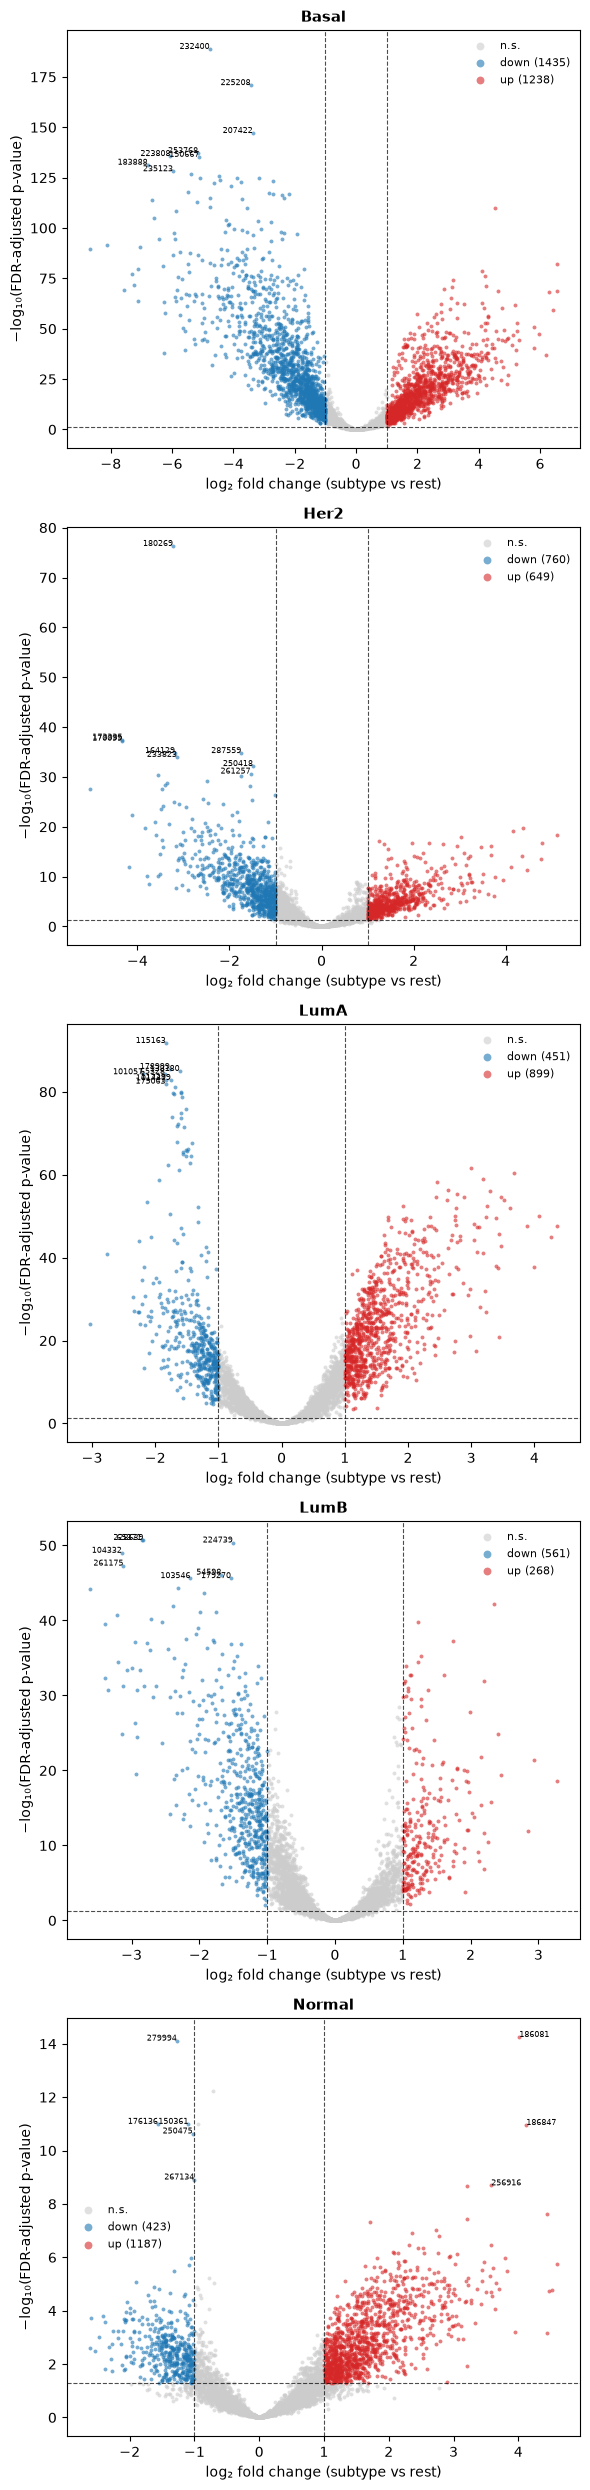

In [7]:
fig = plot_all_volcanos(
    results,
    fdr_threshold=FDR_THRESHOLD,
    log2fc_threshold=LOG2FC_THRESHOLD,
    n_label=8,
    ncols=1,
)
plt.show()

## Known Marker Validation

A credible DGE result should recover established PAM50 biomarkers. We check whether canonical markers from the literature appear in our significant genes.

Genes are stored as versioned Ensembl IDs (e.g. `ENSG00000141736.14`), so we match on the base ID.


In [8]:
results["gene_base"] = results["gene"].str.split(".").str[0]

rows = []
for subtype, marker_ids in KNOWN_MARKERS.items():
    for ensembl_id in marker_ids:
        hit = results[
            (results["subtype"] == subtype) & (results["gene_base"] == ensembl_id)
        ]
        if hit.empty:
            rows.append({"subtype": subtype, "ensembl_id": ensembl_id,
                         "in_top5000": False, "significant": False,
                         "log2fc": None, "padj": None})
        else:
            r = hit.iloc[0]
            rows.append({"subtype": subtype, "ensembl_id": ensembl_id,
                         "in_top5000": True, "significant": bool(r["significant"]),
                         "log2fc": round(float(r["log2fc"]), 2),
                         "padj": f"{r['padj']:.2e}"})

marker_df = pd.DataFrame(rows)
print(f"Markers in top-5000 variable genes: {marker_df['in_top5000'].sum()} / {len(marker_df)}")
print(f"Markers also significant:           {marker_df['significant'].sum()} / {marker_df['in_top5000'].sum()}")
marker_df

Markers in top-5000 variable genes: 8 / 16
Markers also significant:           7 / 8


,subtype,ensembl_id,in_top5000,significant,log2fc,padj
0,Basal,ENSG00000012048,False,False,NaN,None
1,Basal,ENSG00000186081,True,True,3.04,7.68e-21
2,Basal,ENSG00000143228,True,True,1.51,2.70e-36
3,Basal,ENSG00000166033,False,False,NaN,None
4,HER2,ENSG00000141736,False,False,NaN,None
5,HER2,ENSG00000140443,False,False,NaN,None
6,HER2,ENSG00000132965,False,False,NaN,None
7,LumA,ENSG00000091831,True,True,3.12,3.70e-48
8,LumA,ENSG00000129514,True,True,2.22,1.67e-33
9,LumA,ENSG00000107485,True,True,1.86,1.48e-38


## Pairwise Differential Expression

One-vs-rest shows what makes each subtype unique against the pooled rest. Pairwise compares each pair of subtypes directly, giving sharper fold changes and removing the dilution effect of mixing dissimilar groups into "rest".


In [9]:
pairwise = run_pairwise(
    X=X,
    labels=labels,
    fdr_threshold=FDR_THRESHOLD,
    log2fc_threshold=LOG2FC_THRESHOLD,
)
pairwise = annotate_de_results(pairwise, annotation)
print(f"Pairwise: {len(pairwise):,} rows  |  significant: {pairwise['significant'].sum():,}")
pairwise.head(3)

Pairwise DGE: 10 pairs × 5000 genes = 50000 tests
  Basal    vs Her2      n=(139, 67)
  Basal    vs LumA      n=(139, 421)
  Basal    vs LumB      n=(139, 192)
  Basal    vs Normal    n=(139, 23)
  Her2     vs LumA      n=(67, 421)
  Her2     vs LumB      n=(67, 192)
  Her2     vs Normal    n=(67, 23)
  LumA     vs LumB      n=(421, 192)
  LumA     vs Normal    n=(421, 23)
  LumB     vs Normal    n=(192, 23)
Significant pairs (FDR<0.05, |log2FC|≥1.0): 20567 / 50000


Pairwise: 50,000 rows  |  significant: 20,567


,gene,subtype_a,subtype_b,log2fc,pval,padj,mean_a,mean_b,n_a,n_b,significant,symbol
0,ENSG00000166509.12,Basal,Her2,-4.139507,3.769665e-08,1.643271e-07,2.192265,6.331772,139,67,True,NaN
1,ENSG00000110484.7,Basal,Her2,-6.221160,2.034666e-13,1.781669e-12,5.805762,12.026922,139,67,True,NaN
2,ENSG00000153002.12,Basal,Her2,-0.912087,7.315387e-02,1.122336e-01,4.102785,5.014873,139,67,False,NaN


### Heatmap: Significant DE Genes per Subtype Pair

Each cell shows how many genes are significantly different between the two subtypes. Darker = more distinct. Diagonal is zero (a subtype vs itself).


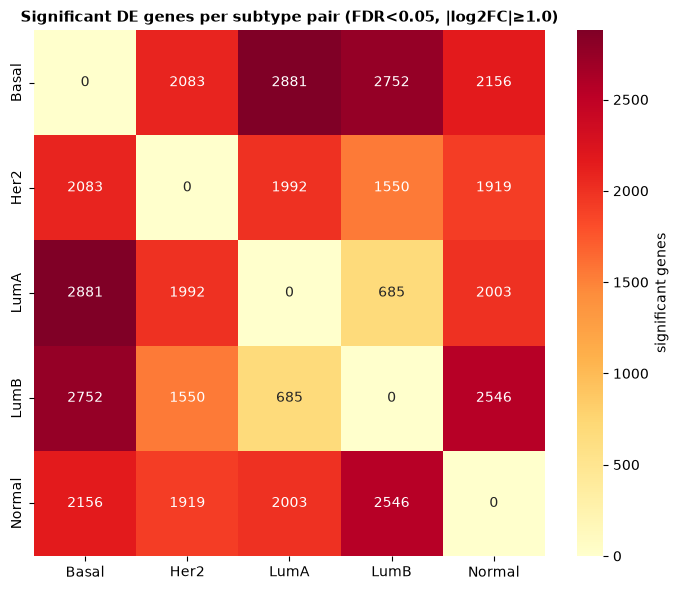

In [10]:
subtypes = sorted(labels.unique())
mat = pd.DataFrame(0, index=subtypes, columns=subtypes)
sig_counts = pairwise[pairwise["significant"]].groupby(["subtype_a", "subtype_b"]).size()
for (a, b), count in sig_counts.items():
    mat.loc[a, b] = count
    mat.loc[b, a] = count  # symmetric

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    mat, annot=True, fmt="d", cmap="YlOrRd", ax=ax,
    cbar_kws={"label": "significant genes"},
)
ax.set_title(
    f"Significant DE genes per subtype pair (FDR<{FDR_THRESHOLD}, |log2FC|≥{LOG2FC_THRESHOLD})",
    fontsize=11, fontweight="bold",
)
plt.tight_layout()
plt.show()

### Top DE Genes: Basal vs LumA

The most biologically contrasting pair — Basal is ER-negative/triple-negative while LumA is strongly ER-positive. Positive log2FC = higher in Basal.


In [11]:
basal_luma = pairwise[(pairwise["subtype_a"] == "Basal") & (pairwise["subtype_b"] == "LumA")]
top_basal_luma = (
    basal_luma[basal_luma["significant"]]
    .nsmallest(20, "padj")
    [["symbol", "gene", "log2fc", "padj", "mean_a", "mean_b"]]
    .reset_index(drop=True)
)
(
    top_basal_luma
    .style
    .format({"log2fc": "{:.2f}", "padj": "{:.2e}", "mean_a": "{:.2f}", "mean_b": "{:.2f}"})
    .background_gradient(subset="log2fc", cmap="RdBu_r", vmin=-6, vmax=6)
)

,symbol,gene,log2fc,padj,mean_a,mean_b
0,nan,ENSG00000232400.1,-5.38,1.08e-193,0.41,5.79
1,nan,ENSG00000253768.1,-6.06,3.74e-149,0.73,6.79
2,nan,ENSG00000225208.1,-4.00,1.02e-142,0.18,4.18
3,nan,ENSG00000150667.8,-5.44,1.18e-141,4.31,9.75
4,nan,ENSG00000183888.4,-7.40,1.82e-141,1.03,8.43
5,nan,ENSG00000236313.1,-6.18,2.92e-138,0.71,6.90
6,nan,ENSG00000279685.2,-4.63,1.31e-137,0.64,5.26
7,nan,ENSG00000252621.1,-5.98,2.27e-137,0.64,6.62
8,nan,ENSG00000244402.3,-5.39,6.72e-136,0.50,5.89
9,nan,ENSG00000260009.1,-2.96,1.64e-127,0.36,3.32


## Save Results


In [12]:
for df, key, drop_cols in [
    (results,  InterimFile.DE_RESULTS,       ["gene_base", "symbol"]),
    (pairwise, InterimFile.PAIRWISE_RESULTS, ["symbol"]),
]:
    out = interim_file(key)
    df.drop(columns=drop_cols, errors="ignore").to_csv(out, index=False)
    print(f"Saved {out.name}  ({len(df):,} rows)")

Saved de_results.csv.gz  (25,000 rows)
Saved pairwise_results.csv.gz  (50,000 rows)
